# Modelle – Betrugserkennung bei Strom und Gas
**Team 5 (Roland, Leo, Tobias)** · Meilenstein 3

Wir vergleichen drei Algorithmen mit denselben Features und derselben Cross-Validation, tunen den besten und speichern ihn.

Daten: `data/fd_features.csv` (aus `06_features.ipynb`) · Split: `data/fd_split.csv` · Bewertung: `fd_utils.py`

| # | Schritt |
|---|---|
| 1 | Setup und Daten laden |
| 2 | Baseline zum Vergleich |
| 3 | Modell 1: logistische Regression mit den neuen Features |
| 4 | Modell 2: Random Forest |
| 5 | Modell 3: AdaBoost |
| 6 | Vergleich |
| 7 | Tuning des besten Modells |
| 8 | Bestes Modell speichern |

## 1 · Setup und Daten laden

In [2]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

from fd_utils import RANDOM_STATE, cv, evaluate_cv

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

DATA_DIR = Path("data")
MODEL_DIR = Path("models")

In [3]:
df = pd.read_csv(DATA_DIR / "fd_features.csv")
df_split = pd.read_csv(DATA_DIR / "fd_split.csv")
df = df.merge(df_split, on="client_id", how="left")

df_train = df[df["split"] == "train"]

nicht_features = ["client_id", "creation_date", "split", "target"]
X_train = df_train.drop(columns=nicht_features)
y_train = df_train["target"]

print("X_train:", X_train.shape)
print("Betrugsquote:", round(y_train.mean(), 4))

X_train: (108394, 30)
Betrugsquote: 0.0558


Wie in `05_baseline.ipynb` arbeiten wir nur mit dem **Train-Teil** und Cross-Validation. Den Test-Teil laden wir hier gar nicht erst.

## 2 · Baseline zum Vergleich
Die logistische Regression aus `05_baseline.ipynb` (nur die Spalten aus `fd_cleaned.csv`). Die Pipeline sucht sich ihre Spalten selbst aus, deshalb funktioniert sie auch mit der größeren Tabelle.

In [4]:
baseline = joblib.load(MODEL_DIR / "fd_baseline.joblib")

ergebnisse = evaluate_cv(baseline, X_train, y_train, "Baseline: LogReg (fd_cleaned)")
ergebnisse

,ROC-AUC,ROC-AUC std,Recall,Precision
Baseline: LogReg (fd_cleaned),0.804,0.007,0.743,0.142


## 3 · Modell 1: logistische Regression mit den neuen Features
Gleiche Vorbereitung wie in der Baseline, nur mit allen neuen Spalten aus `06_features.ipynb`. Alle Verbrauchs- und Sprung-Spalten sind schief verteilt und bekommen deshalb `log(1 + x)`.

In [5]:
kategorien = ["disrict", "client_catg", "region"]

schief = ["cons_median_elec", "cons_mean_elec", "cons_std_elec",
          "cons_median_gaz", "cons_mean_gaz", "cons_std_gaz",
          "month_median_elec", "month_std_elec", "month_median_gaz", "month_std_gaz",
          "max_drop", "max_rise", "mean_abs_change", "trend_ratio", "cv_elec", "cv_gaz"]

zahlen = [spalte for spalte in X_train.columns if spalte not in kategorien + schief]
print("Zahlen ohne log:", zahlen)

vorbereitung = ColumnTransformer([
    ("kategorien", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100), kategorien),
    ("schief", Pipeline([("log", FunctionTransformer(np.log1p)), ("scaler", StandardScaler())]), schief),
    ("zahlen", StandardScaler(), zahlen),
])

logreg = Pipeline([
    ("vorbereitung", vorbereitung),
    ("logreg", LogisticRegression(class_weight="balanced", max_iter=2000)),
])

ergebnisse = pd.concat([ergebnisse, evaluate_cv(logreg, X_train, y_train, "LogReg: neue Features")])
ergebnisse

Zahlen ohne log: ['n_invoices', 'n_counters', 'share_gas', 'share_zero', 'any_index_backwards', 'share_statue_not_ok', 'contract_age_years', 'active_years', 'share_remarque_6', 'share_remarque_8', 'share_remarque_9']


,ROC-AUC,ROC-AUC std,Recall,Precision
Baseline: LogReg (fd_cleaned),0.804,0.007,0.743,0.142
LogReg: neue Features,0.813,0.006,0.750,0.146


## 4 · Modell 2: Random Forest
Bäume brauchen kein Skalieren und kein Logarithmieren. Die Codes von Region und Bezirk können sie direkt als Zahlen benutzen.

* `class_weight="balanced"` wegen der wenigen Betrugsfälle
* `min_samples_leaf=20`, damit die Bäume nicht jeden einzelnen Kunden auswendig lernen

In [6]:
rf = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=20,
    class_weight="balanced",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

ergebnisse = pd.concat([ergebnisse, evaluate_cv(rf, X_train, y_train, "Random Forest")])
ergebnisse

,ROC-AUC,ROC-AUC std,Recall,Precision
Baseline: LogReg (fd_cleaned),0.804,0.007,0.743,0.142
LogReg: neue Features,0.813,0.006,0.750,0.146
Random Forest,0.844,0.004,0.667,0.197


## 5 · Modell 3: AdaBoost
AdaBoost (aus week07, Ensemble-Methoden) baut viele sehr kleine Bäume nacheinander. Jeder neue Baum schaut sich besonders die Kunden an, bei denen die vorherigen falsch lagen.

AdaBoost hat kein `class_weight`. Für die ROC-AUC ist das egal, weil sie nur die Reihenfolge der Kunden bewertet.

In [7]:
ada = AdaBoostClassifier(n_estimators=200, random_state=RANDOM_STATE)

ergebnisse = pd.concat([ergebnisse, evaluate_cv(ada, X_train, y_train, "AdaBoost")])
ergebnisse

,ROC-AUC,ROC-AUC std,Recall,Precision
Baseline: LogReg (fd_cleaned),0.804,0.007,0.743,0.142
LogReg: neue Features,0.813,0.006,0.750,0.146
Random Forest,0.844,0.004,0.667,0.197
AdaBoost,0.816,0.005,0.010,0.343


## 6 · Vergleich

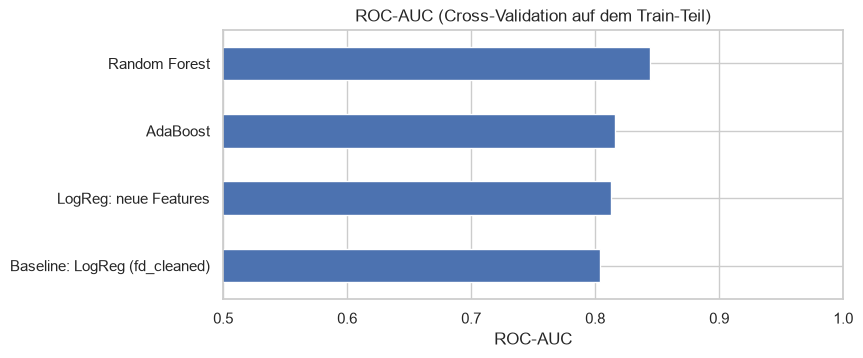

,ROC-AUC,ROC-AUC std,Recall,Precision
Random Forest,0.844,0.004,0.667,0.197
AdaBoost,0.816,0.005,0.010,0.343
LogReg: neue Features,0.813,0.006,0.750,0.146
Baseline: LogReg (fd_cleaned),0.804,0.007,0.743,0.142


In [8]:
ergebnisse["ROC-AUC"].sort_values().plot(kind="barh", figsize=(8, 3.5))
plt.title("ROC-AUC (Cross-Validation auf dem Train-Teil)")
plt.xlabel("ROC-AUC")
plt.xlim(0.5, 1)
plt.show()

ergebnisse.sort_values("ROC-AUC", ascending=False)

**Was fällt auf?**
* Mit den neuen Features wird die logistische Regression etwas besser (0,804 → 0,813).
* Der **Random Forest ist am besten** (0,844). Bäume kommen mit schiefen Werten, Ausreißern und Zusammenhängen wie "erst hoch, dann runter" (Nullrechnungen, EDA 9.2) besser klar.
* AdaBoost (0,816) liegt nur knapp über der logistischen Regression. Recall 1 % heißt nicht, dass AdaBoost schlecht sortiert: Ohne `class_weight` sagt es bei der Schwelle 0,5 fast nie "Betrug". Für den Vergleich zählt die ROC-AUC.
* Die Unterschiede zwischen den Folds sind klein (std 0,004–0,007). Die Reihenfolge ist also kein Zufall.

**Entscheidung:** Wir tunen den Random Forest (beste ROC-AUC).

## 7 · Tuning des Random Forest
Wir probieren mit `RandomizedSearchCV` (wie in week06) 10 zufällige Kombinationen aus und bewerten jede mit denselben 5 Folds. Das dauert ein paar Minuten.

| Parameter | Bedeutung |
|---|---|
| `n_estimators` | Anzahl Bäume |
| `max_depth` | wie tief ein Baum werden darf (`None` = unbegrenzt) |
| `min_samples_leaf` | wie viele Kunden mindestens in einem Blatt sein müssen |
| `max_features` | wie viele Spalten jeder Baum bei einer Frage ausprobieren darf |

In [9]:
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [5, 10, 20, 50],
    "max_features": ["sqrt", 0.3, 0.5],
}

rs = RandomizedSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    param_grid,
    n_iter=10,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
rs.fit(X_train, y_train)

print("Beste CV-ROC-AUC:", round(rs.best_score_, 3))
print("Beste Parameter: ", rs.best_params_)

Beste CV-ROC-AUC: 0.847
Beste Parameter:  {'n_estimators': 300, 'min_samples_leaf': 20, 'max_features': 0.3, 'max_depth': 20}


In [10]:
# Die 5 besten Kombinationen
tuning = pd.DataFrame(rs.cv_results_)
spalten = ["param_n_estimators", "param_max_depth", "param_min_samples_leaf",
           "param_max_features", "mean_test_score", "std_test_score"]
tuning[spalten].sort_values("mean_test_score", ascending=False).head().round(4)

,param_n_estimators,param_max_depth,param_min_samples_leaf,param_max_features,mean_test_score,std_test_score
2,300,20,20,0.3,0.8467,0.0045
3,300,20,10,0.3,0.8463,0.0049
1,100,20,20,0.3,0.8458,0.0042
6,200,20,10,0.3,0.8458,0.0045
9,100,10,20,0.5,0.8449,0.0042


In [11]:
# Getuntes Modell mit allen Metriken bewerten, damit es in die Tabelle passt
rf_tuned = rs.best_estimator_

ergebnisse = pd.concat([ergebnisse, evaluate_cv(rf_tuned, X_train, y_train, "Random Forest (getunt)")])
ergebnisse.sort_values("ROC-AUC", ascending=False)

,ROC-AUC,ROC-AUC std,Recall,Precision
Random Forest (getunt),0.847,0.005,0.664,0.202
Random Forest,0.844,0.004,0.667,0.197
AdaBoost,0.816,0.005,0.010,0.343
LogReg: neue Features,0.813,0.006,0.750,0.146
Baseline: LogReg (fd_cleaned),0.804,0.007,0.743,0.142


**Was fällt auf?**
* Das Tuning bringt nur wenig: 0,844 → **0,847**. Die Standard-Einstellungen waren schon gut.
* Bei allen guten Kombinationen ist `max_depth` begrenzt (20) und `max_features` bei 0,3. Die Bäume dürfen also nicht beliebig tief werden und schauen bei jeder Frage nur auf einen Teil der Spalten.

## 8 · Bestes Modell speichern
`RandomizedSearchCV` hat das beste Modell am Ende schon auf dem ganzen Train-Teil trainiert. Wir speichern es für `08_fehleranalyse.ipynb` und `09_final.ipynb`.

In [12]:
MODEL_DIR.mkdir(exist_ok=True)
joblib.dump(rf_tuned, MODEL_DIR / "fd_best_model.joblib")
ergebnisse.to_csv(MODEL_DIR / "cv_ergebnisse.csv")

print("Gespeichert: models/fd_best_model.joblib und models/cv_ergebnisse.csv")

Gespeichert: models/fd_best_model.joblib und models/cv_ergebnisse.csv


## Fazit

| Modell | ROC-AUC (CV) |
|---|---|
| Baseline: LogReg (fd_cleaned) | 0,804 |
| LogReg: neue Features | 0,813 |
| AdaBoost | 0,816 |
| Random Forest | 0,844 |
| **Random Forest (getunt)** | **0,847** |

* Das beste Modell schlägt die Baseline um 0,043 ROC-AUC.
* Gespeichert als `models/fd_best_model.joblib`. Weiter geht es mit `08_fehleranalyse.ipynb`.